# 04 · Mixed models

The `sleepstudy` data: reaction times of 18 subjects over 10 days of sleep deprivation. Subjects differ both in their baseline and in how fast they slow down, so the model has a random intercept and a random slope.

In [1]:
import warnings

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore", category=FutureWarning)
DATA = "../tests/data"
sleep = pd.read_csv(f"{DATA}/sleepstudy.csv")
fit = smf.mixedlm("Reaction ~ Days", sleep, groups="Subject", re_formula="~Days").fit()
fit.summary().tables[1]

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,251.405,6.825,36.838,0.000,238.029,264.781
Days,10.467,1.546,6.771,0.000,7.438,13.497
Subject Var,612.096,11.881,,,,
Subject x Days Cov,9.605,1.821,,,,
Days Var,35.072,0.610,,,,


In [2]:
from checkmodel import check_model

report = check_model(fit)
report

# Model checks: MixedLM (gaussian, identity link), n = 180

Posterior predictive check: OK: Model-predicted data resemble the observed data (mean p = 0.460, sd p = 0.520).
Normality of residuals: Warning: Non-normality of residuals detected (p < .001).
Normality of random effects: OK: Random effects 'Subject: (Intercept)' appear as normally distributed (p = 0.428).
  OK: Random effects 'Subject: Days' appear as normally distributed (p = 0.898).
Homogeneity of variance: Warning: Heteroscedasticity (non-constant error variance) detected (p < .001).
Influential observations: Warning: 4 outliers detected: cases 7, 56, 59, 130 (Cook's distance > 0.696).
Singularity: OK: The random-effects structure is not singular.
Convergence: OK: Model converged.

Skipped:
  collinearity: Not enough model terms to check for multicollinearity (need at least two).

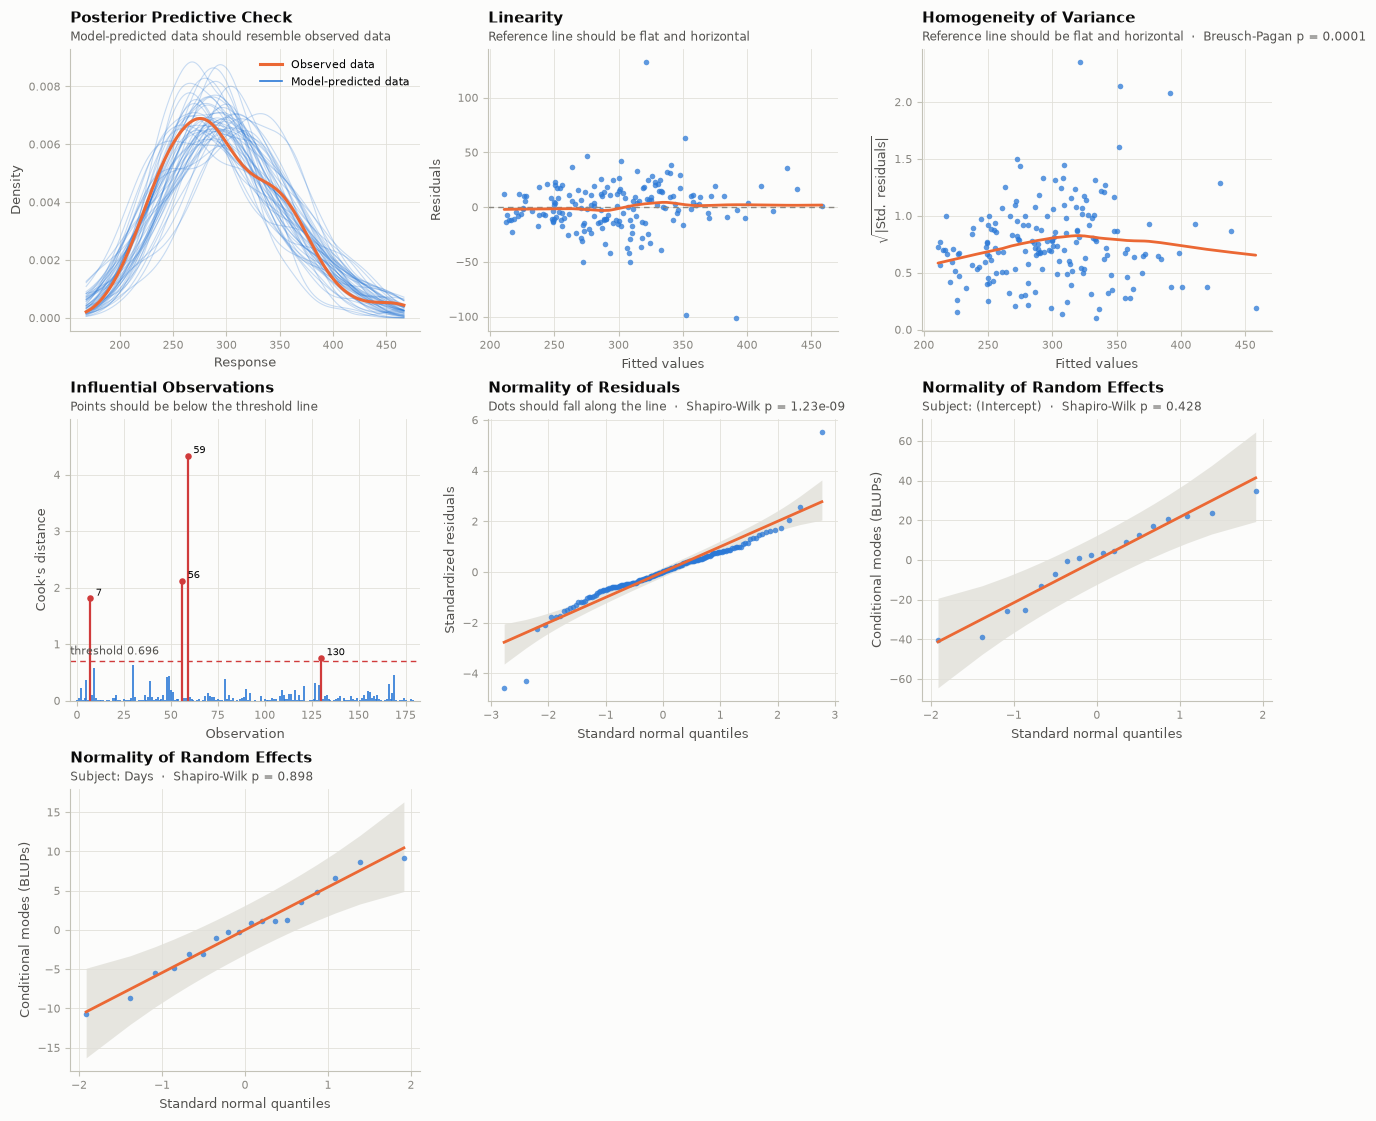

In [3]:
report.plot();

## Variance decomposition

The ICC is the share of variance due to differences between subjects; Nakagawa's R² splits explained variance into the part due to the fixed effects (marginal) and to fixed plus random effects (conditional).

In [4]:
from checkmodel import icc, r2, variance_components

icc(fit)

# Intraclass Correlation Coefficient
    Adjusted ICC: 0.722
  Unadjusted ICC: 0.521

In [5]:
r2(fit)

# R2 for Mixed Models
  Conditional R2: 0.799
     Marginal R2: 0.279

In [6]:
variance_components(fit)

VarianceComponents(fixed=908.953362623097, random=1698.0791291160313, residual=654.9404769803164)

## Random effects

The conditional modes (BLUPs) of each subject should look normal:

In [7]:
from checkmodel import check_normality

re = check_normality(fit, effects="random")
re.plot();

## Singular fits

When a random-effect variance belongs at zero, statsmodels' default optimizer may stop just short of it. `check_convergence()` notices; refitting with Powell's method reaches the boundary and `check_singularity()` flags it, as lme4 would.

In [8]:
import numpy as np

rng = np.random.default_rng(1)
df = pd.DataFrame({"g": np.repeat(np.arange(20), 10), "x": rng.normal(size=200)})
df["y"] = 1 + 0.5 * df.x + rng.normal(size=200)  # no group effect at all
flat = smf.mixedlm("y ~ x", df, groups="g").fit(method="powell")

from checkmodel import check_singularity
check_singularity(flat)

C:\Users\rt01570\AppData\Local\Temp\ipykernel_19340\646611718.py:6: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  flat = smf.mixedlm("y ~ x", df, groups="g").fit(method="powell")
